# Simulación y probabilidad · Inferencia y remuestreo

Estadística inferencial con el ordenador en lugar de fórmulas: el bootstrap para construir intervalos de confianza de cualquier estadístico, los tests de permutación para contrastar hipótesis sin suponer normalidad y la inferencia bayesiana con el modelo beta-binomial, que se resuelve de forma exacta y también por simulación con Metropolis-Hastings. Cada resultado se compara con su equivalente clásico de `scipy.stats`.

## 1. Bootstrap de la media

Simular 40 tiempos de espera de la guagua (en minutos, distribución exponencial de media 8) y construir un intervalo de confianza del 95 % para la media con el bootstrap de percentiles: remuestrear con reemplazo 10 000 veces, calcular la media de cada remuestra y tomar los percentiles 2,5 y 97,5. Compararlo con el intervalo $t$ de `scipy.stats.t.interval`.

Media muestral: 10.47 min
Error estándar: bootstrap 1.972, fórmula s/√n 2.024
IC 95 % bootstrap: [7.06, 14.72]
IC 95 % t:         [6.37, 14.56]


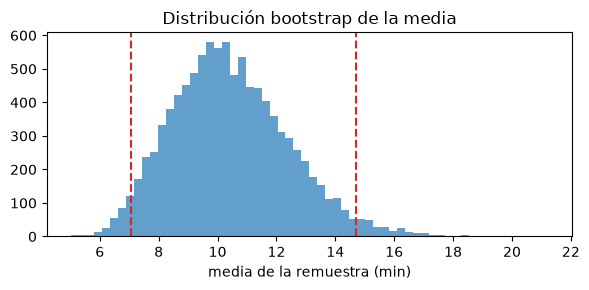

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(1)
esperas = rng.exponential(8, 40)
B = 10_000


def bootstrap(muestra, estadistico, B, rng):
    indices = rng.integers(0, len(muestra), size=(B, len(muestra)))
    return estadistico(muestra[indices], axis=1)


medias = bootstrap(esperas, np.mean, B, rng)
ic_boot = np.percentile(medias, [2.5, 97.5])
ic_t = stats.t.interval(0.95, df=len(esperas) - 1, loc=esperas.mean(), scale=stats.sem(esperas))
print(f"Media muestral: {esperas.mean():.2f} min")
print(f"Error estándar: bootstrap {medias.std(ddof=1):.3f}, fórmula s/√n {stats.sem(esperas):.3f}")
print(f"IC 95 % bootstrap: [{ic_boot[0]:.2f}, {ic_boot[1]:.2f}]")
print(f"IC 95 % t:         [{ic_t[0]:.2f}, {ic_t[1]:.2f}]")
assert abs(medias.std(ddof=1) - stats.sem(esperas)) < 0.1 * stats.sem(esperas)
assert ic_boot[0] < esperas.mean() < ic_boot[1]

plt.figure(figsize=(6, 3))
plt.hist(medias, bins=60, color="tab:blue", alpha=0.7)
for x in ic_boot:
    plt.axvline(x, color="tab:red", ls="--")
plt.xlabel("media de la remuestra (min)")
plt.title("Distribución bootstrap de la media")
plt.tight_layout()
plt.show()

## 2. Bootstrap de la mediana

La mediana no tiene una fórmula sencilla para su error estándar, pero el bootstrap funciona igual. Calcular el intervalo del 95 % para la mediana de las esperas con la función propia y con `scipy.stats.bootstrap`, tanto por percentiles como con el método BCa (corregido de sesgo y acelerado), y comparar los tres.

In [2]:
medianas = bootstrap(esperas, np.median, B, rng)
ic_propio = np.percentile(medianas, [2.5, 97.5])
ic_pct = stats.bootstrap((esperas,), np.median, n_resamples=B, method="percentile", rng=0).confidence_interval
ic_bca = stats.bootstrap((esperas,), np.median, n_resamples=B, method="BCa", rng=0).confidence_interval
print(f"Mediana muestral: {np.median(esperas):.2f} min")
print(f"{'propio (percentiles)':22}[{ic_propio[0]:.2f}, {ic_propio[1]:.2f}]")
print(f"{'scipy (percentiles)':22}[{ic_pct.low:.2f}, {ic_pct.high:.2f}]")
print(f"{'scipy (BCa)':22}[{ic_bca.low:.2f}, {ic_bca.high:.2f}]")
assert abs(ic_propio[0] - ic_pct.low) < 0.5 and abs(ic_propio[1] - ic_pct.high) < 0.5

Mediana muestral: 7.29 min
propio (percentiles)  [3.84, 9.45]
scipy (percentiles)   [3.84, 9.45]
scipy (BCa)           [3.84, 9.45]


## 3. ¿Cubren lo que prometen?

Un intervalo del 95 % debería contener el valor verdadero en el 95 % de las muestras. Repetir 1000 veces el experimento con muestras de solo 12 esperas exponenciales (media real 8) y contar cuántas veces el intervalo $t$ y el bootstrap de percentiles contienen la media real. Con datos tan asimétricos y tan pocos, ninguno llega del todo al 95 %.

In [3]:
rng_cob = np.random.default_rng(3)
repeticiones, tam = 1000, 12
cubre_t = cubre_boot = 0
for _ in range(repeticiones):
    m = rng_cob.exponential(8, tam)
    bajo, alto = stats.t.interval(0.95, df=tam - 1, loc=m.mean(), scale=stats.sem(m))
    cubre_t += bajo <= 8 <= alto
    bajo, alto = np.percentile(bootstrap(m, np.mean, 2000, rng_cob), [2.5, 97.5])
    cubre_boot += bajo <= 8 <= alto
print(f"Cobertura del intervalo t:         {cubre_t / repeticiones:.1%}")
print(f"Cobertura del bootstrap percentil: {cubre_boot / repeticiones:.1%}")
assert 0.80 < cubre_boot / repeticiones < cubre_t / repeticiones < 0.96

Cobertura del intervalo t:         91.5%
Cobertura del bootstrap percentil: 88.2%


El bootstrap de percentiles es algo más optimista con muestras pequeñas: remuestrear no puede inventar la variabilidad de la cola que la muestra no ha visto. Con más datos, o con BCa, las coberturas se acercan al 95 %.

## 4. Diferencia de medias

Dos fincas de plataneras prueban abonos distintos y miden los kilos por racimo (30 y 35 racimos simulados). Construir un intervalo bootstrap del 95 % para la diferencia de medias remuestreando cada grupo por separado y compararlo con el intervalo de Welch que da `ttest_ind(..., equal_var=False).confidence_interval()`.

In [4]:
rng4 = np.random.default_rng(4)
abono_a = rng4.normal(38, 5, 30)
abono_b = rng4.normal(41, 7, 35)

diferencias = bootstrap(abono_b, np.mean, B, rng4) - bootstrap(abono_a, np.mean, B, rng4)
ic_dif = np.percentile(diferencias, [2.5, 97.5])
welch = stats.ttest_ind(abono_b, abono_a, equal_var=False).confidence_interval(0.95)
print(f"Diferencia observada (B − A): {abono_b.mean() - abono_a.mean():.2f} kg")
print(f"IC 95 % bootstrap: [{ic_dif[0]:.2f}, {ic_dif[1]:.2f}]")
print(f"IC 95 % Welch:     [{welch.low:.2f}, {welch.high:.2f}]")
assert abs(ic_dif[0] - welch.low) < 0.5 and abs(ic_dif[1] - welch.high) < 0.5

Diferencia observada (B − A): 4.08 kg
IC 95 % bootstrap: [1.33, 6.72]
IC 95 % Welch:     [1.25, 6.90]


## 5. Test de permutación a mano

Si el abono no influye, las etiquetas A y B son intercambiables. Contrastarlo mezclando las 65 medidas al azar 20 000 veces, repartiéndolas en grupos de 30 y 35 y contando en qué proporción de las permutaciones la diferencia de medias es al menos tan extrema como la observada (valor p bilateral). Compararlo con el valor p de `ttest_ind`.

Diferencia observada: 4.08 kg
p por permutación: 0.0052
p de ttest_ind:     0.0054


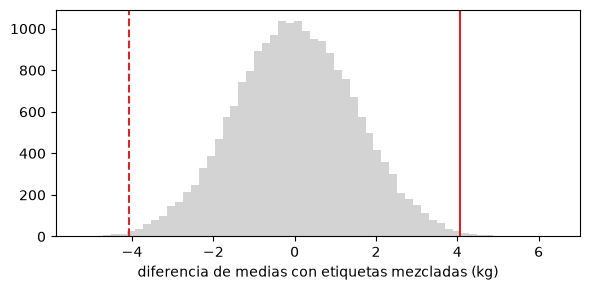

In [5]:
def test_permutacion(a, b, permutaciones, rng):
    observada = b.mean() - a.mean()
    juntos = np.concatenate([a, b])
    mezclas = rng.permuted(np.tile(juntos, (permutaciones, 1)), axis=1)
    dif = mezclas[:, len(a):].mean(axis=1) - mezclas[:, : len(a)].mean(axis=1)
    return observada, (np.sum(np.abs(dif) >= abs(observada)) + 1) / (permutaciones + 1), dif


observada, p_perm, dif_nula = test_permutacion(abono_a, abono_b, 20_000, np.random.default_rng(5))
p_t = stats.ttest_ind(abono_b, abono_a).pvalue
print(f"Diferencia observada: {observada:.2f} kg")
print(f"p por permutación: {p_perm:.4f}")
print(f"p de ttest_ind:     {p_t:.4f}")
assert abs(p_perm - p_t) < 0.01

plt.figure(figsize=(6, 3))
plt.hist(dif_nula, bins=60, color="lightgray")
plt.axvline(observada, color="tab:red")
plt.axvline(-observada, color="tab:red", ls="--")
plt.xlabel("diferencia de medias con etiquetas mezcladas (kg)")
plt.tight_layout()
plt.show()

Se suma 1 al numerador y al denominador para contar la propia muestra observada como una permutación más: así el valor p nunca es exactamente 0, lo que sería imposible de afirmar con un número finito de permutaciones.

## 6. `scipy.stats.permutation_test` y el test exacto

Repetir el contraste con `scipy.stats.permutation_test` y comprobar que el valor p se parece al propio. Después, con dos grupos muy pequeños (5 y 4 tiempos de carga de una web con dos servidores), enumerar con `itertools.combinations` las 126 formas de repartir las etiquetas y obtener el valor p exacto, comparándolo con el de `permutation_test`, que también enumera todas cuando hay pocas.

In [6]:
from itertools import combinations


def dif_medias(a, b, axis=-1):
    return np.mean(b, axis=axis) - np.mean(a, axis=axis)


res = stats.permutation_test((abono_a, abono_b), dif_medias, n_resamples=20_000, rng=6)
print(f"scipy permutation_test: p = {res.pvalue:.4f} (propio {p_perm:.4f})")
assert abs(res.pvalue - p_perm) < 0.01

servidor_1 = np.array([212, 198, 240, 225, 207.0])
servidor_2 = np.array([251, 239, 262, 230.0])
juntos = np.concatenate([servidor_1, servidor_2])
obs = servidor_2.mean() - servidor_1.mean()
difs = []
for grupo_1 in combinations(range(len(juntos)), len(servidor_1)):
    mascara = np.zeros(len(juntos), bool)
    mascara[list(grupo_1)] = True
    difs.append(juntos[~mascara].mean() - juntos[mascara].mean())
difs = np.array(difs)
total = len(difs)
p_valor_absoluto = np.mean(np.abs(difs) >= abs(obs) - 1e-12)
p_doble = min(1, 2 * min(np.mean(difs >= obs - 1e-12), np.mean(difs <= obs + 1e-12)))
p_scipy = stats.permutation_test((servidor_1, servidor_2), dif_medias).pvalue
print(f"Repartos posibles: {total}")
print(f"p exacto con |diferencia|: {p_valor_absoluto:.4f}")
print(f"p exacto doblando la cola menor: {p_doble:.4f}; scipy: {p_scipy:.4f}")
assert total == 126 and np.isclose(p_doble, p_scipy)

scipy permutation_test: p = 0.0055 (propio 0.0052)
Repartos posibles: 126
p exacto con |diferencia|: 0.0397
p exacto doblando la cola menor: 0.0476; scipy: 0.0476


Con distribuciones de permutación asimétricas hay dos convenios para el valor p bilateral: contar las diferencias con valor absoluto al menos tan grande (como en el ejercicio 5) o doblar el valor p de la cola más pequeña, que es lo que hace `permutation_test`. Con muestras grandes coinciden casi siempre; con 126 repartos se nota.

## 7. Inferencia bayesiana: tasa de clics

Una web de excursiones en La Gomera mostró un anuncio a 250 visitantes y 18 hicieron clic. Con una a priori $\text{Beta}(2, 20)$ (se espera una tasa en torno al 10 %), la a posteriori es $\text{Beta}(2 + 18,\ 20 + 232)$. Calcular la media a posteriori y el intervalo creíble del 95 % con `stats.beta`, comprobar el resultado con una aproximación en rejilla (a priori × verosimilitud binomial, normalizada) y dibujar las tres curvas.

A posteriori Beta(20, 252): media 0.0735, IC creíble 95 % [0.0457, 0.1073]
Estimación frecuentista: 0.0720
Rejilla: media 0.0735, IC [0.0457, 0.1073]


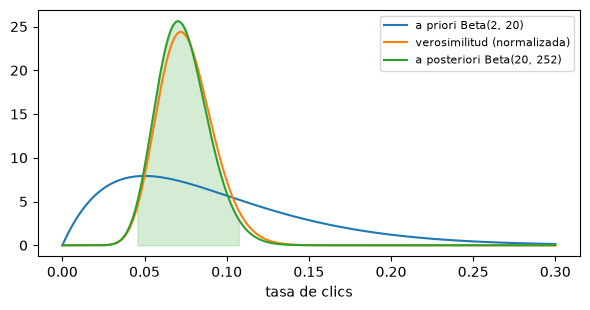

In [7]:
a0, b0 = 2, 20
visitas, clics = 250, 18
a1, b1 = a0 + clics, b0 + visitas - clics
posterior = stats.beta(a1, b1)
creible = posterior.ppf([0.025, 0.975])
print(f"A posteriori Beta({a1}, {b1}): media {posterior.mean():.4f}, IC creíble 95 % [{creible[0]:.4f}, {creible[1]:.4f}]")
print(f"Estimación frecuentista: {clics / visitas:.4f}")

p = np.linspace(0, 0.3, 30_001)
dp = p[1] - p[0]
apriori = stats.beta(a0, b0).pdf(p)
verosimilitud = stats.binom.pmf(clics, visitas, p)
rejilla = apriori * verosimilitud
rejilla /= rejilla.sum() * dp
acumulada = np.cumsum(rejilla) * dp
creible_rejilla = p[np.searchsorted(acumulada, [0.025, 0.975])]
print(f"Rejilla: media {np.sum(p * rejilla) * dp:.4f}, IC [{creible_rejilla[0]:.4f}, {creible_rejilla[1]:.4f}]")
assert np.allclose(rejilla, posterior.pdf(p), atol=1e-2)
assert np.allclose(creible_rejilla, creible, atol=1e-4)

plt.figure(figsize=(6, 3.2))
plt.plot(p, apriori, label="a priori Beta(2, 20)")
plt.plot(p, verosimilitud / (verosimilitud.sum() * dp), label="verosimilitud (normalizada)")
plt.plot(p, posterior.pdf(p), label=f"a posteriori Beta({a1}, {b1})")
plt.fill_between(p, posterior.pdf(p), where=(p >= creible[0]) & (p <= creible[1]), alpha=0.2, color="tab:green")
plt.xlabel("tasa de clics")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Actualización secuencial

Los datos llegan día a día. Partir de la misma a priori y actualizarla cada día con los clics de ese día, usando la a posteriori de ayer como a priori de hoy. Comprobar que el resultado final es idéntico a procesar todos los datos de golpe y mostrar cómo se estrecha el intervalo creíble.

In [8]:
rng8 = np.random.default_rng(8)
visitas_dia = rng8.integers(20, 60, 10)
clics_dia = rng8.binomial(visitas_dia, 0.08)

a, b = a0, b0
print(f"{'día':>3}{'visitas':>9}{'clics':>7}{'media':>9}{'IC creíble 95 %':>22}")
for dia, (v, c) in enumerate(zip(visitas_dia, clics_dia), 1):
    a, b = a + c, b + v - c
    bajo, alto = stats.beta(a, b).ppf([0.025, 0.975])
    print(f"{dia:3}{v:9}{c:7}{a / (a + b):9.4f}   [{bajo:.4f}, {alto:.4f}]  ancho {alto - bajo:.4f}")
assert (a, b) == (a0 + clics_dia.sum(), b0 + visitas_dia.sum() - clics_dia.sum())

día  visitas  clics    media       IC creíble 95 %
  1       48      3   0.0714   [0.0239, 0.1418]  ancho 0.1179
  2       33      2   0.0680   [0.0280, 0.1236]  ancho 0.0956
  3       29      2   0.0682   [0.0319, 0.1168]  ancho 0.0849
  4       59      2   0.0576   [0.0293, 0.0947]  ancho 0.0654
  5       27      2   0.0596   [0.0323, 0.0946]  ancho 0.0623
  6       32      1   0.0560   [0.0311, 0.0876]  ancho 0.0565
  7       45      2   0.0542   [0.0314, 0.0828]  ancho 0.0513
  8       51      2   0.0520   [0.0312, 0.0777]  ancho 0.0465
  9       45      2   0.0512   [0.0316, 0.0750]  ancho 0.0434
 10       54      6   0.0584   [0.0386, 0.0820]  ancho 0.0434


## 9. El peso de la a priori

Comparar tres a prioris (uniforme $\text{Beta}(1,1)$, la informativa $\text{Beta}(2,20)$ y una muy confiada y equivocada, $\text{Beta}(60, 140)$, centrada en el 30 %) con pocos datos (25 visitas, 2 clics) y con muchos (2500 visitas, 200 clics). Comprobar que con muchos datos las tres medias a posteriori casi coinciden.

In [9]:
apriores = {"uniforme": (1, 1), "informativa": (2, 20), "confiada": (60, 140)}
medias_post = {}
for v, c in [(25, 2), (2500, 200)]:
    print(f"{v} visitas, {c} clics:")
    for nombre, (pa, pb) in apriores.items():
        medias_post[nombre, v] = (pa + c) / (pa + pb + v)
        print(f"  {nombre:12} media a posteriori {medias_post[nombre, v]:.4f}")
rango = lambda v: max(medias_post[n, v] for n in apriores) - min(medias_post[n, v] for n in apriores)
print(f"Diferencia máxima entre a prioris: {rango(25):.4f} con pocos datos, {rango(2500):.4f} con muchos")
assert rango(2500) < 0.02 < rango(25)

25 visitas, 2 clics:
  uniforme     media a posteriori 0.1111
  informativa  media a posteriori 0.0851
  confiada     media a posteriori 0.2756
2500 visitas, 200 clics:
  uniforme     media a posteriori 0.0803
  informativa  media a posteriori 0.0801
  confiada     media a posteriori 0.0963
Diferencia máxima entre a prioris: 0.1904 con pocos datos, 0.0162 con muchos


La media a posteriori es una media ponderada entre la media a priori y la proporción observada, con pesos $a+b$ y $n$: la a priori vale como $a+b$ observaciones ficticias, por eso la confiada (200 visitas ficticias) domina con 25 datos y apenas pesa con 2500.

## 10. Test A/B por simulación

La web prueba dos diseños: A recibe 1200 visitas con 84 clics y B 1150 visitas con 104 clics. Con a priori uniforme, obtener por simulación la probabilidad de que B sea mejor que A, el aumento relativo esperado con su intervalo creíble y la pérdida esperada de elegir cada uno. Comprobar $P(B > A)$ con una integración numérica.

In [10]:
from scipy import integrate

post_a = stats.beta(1 + 84, 1 + 1200 - 84)
post_b = stats.beta(1 + 104, 1 + 1150 - 104)
rng10 = np.random.default_rng(10)
ma = post_a.rvs(200_000, random_state=rng10)
mb = post_b.rvs(200_000, random_state=rng10)

prob_b = np.mean(mb > ma)
aumento = mb / ma - 1
exacta, _ = integrate.quad(lambda x: post_a.pdf(x) * post_b.sf(x), 0, 1, points=[0.07, 0.09])
print(f"Tasa A ≈ {ma.mean():.4f}, tasa B ≈ {mb.mean():.4f}")
print(f"P(B > A): simulación {prob_b:.4f}, integración {exacta:.4f}")
print(f"Aumento relativo de B: media {aumento.mean():.1%}, IC 95 % [{np.percentile(aumento, 2.5):.1%}, {np.percentile(aumento, 97.5):.1%}]")
print(f"Pérdida esperada (en tasa de clics): elegir A {np.mean(np.maximum(mb - ma, 0)):.5f}, elegir B {np.mean(np.maximum(ma - mb, 0)):.5f}")
assert abs(prob_b - exacta) < 0.005

Tasa A ≈ 0.0707, tasa B ≈ 0.0911
P(B > A): simulación 0.9659, integración 0.9658
Aumento relativo de B: media 30.3%, IC 95 % [-1.8%, 70.1%]
Pérdida esperada (en tasa de clics): elegir A 0.02056, elegir B 0.00015


## 11. Metropolis-Hastings

Cuando la a posteriori no tiene forma conocida se muestrea con MCMC. Escribir un Metropolis-Hastings de paseo aleatorio para la tasa de clics del ejercicio 7, que solo use el logaritmo de a priori × verosimilitud (sin normalizar): proponer $p' = p + \varepsilon$, con $\varepsilon \sim N(0, \sigma)$, y aceptarlo con probabilidad $\min(1, \pi(p')/\pi(p))$. Descartar el calentamiento y comparar la media y el intervalo con los de la a posteriori conjugada.

Aceptación: 63.7%
MCMC:      media 0.0737, IC [0.0462, 0.1076]
Conjugada: media 0.0735, IC [0.0457, 0.1073]


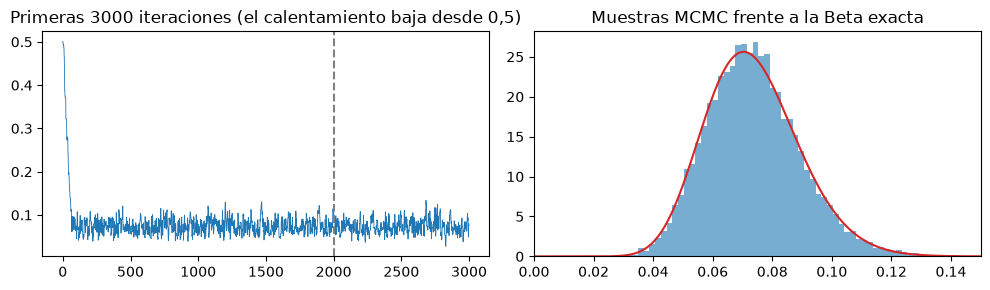

In [11]:
def log_objetivo(p):
    if not 0 < p < 1:
        return -np.inf
    return stats.beta.logpdf(p, a0, b0) + clics * np.log(p) + (visitas - clics) * np.log1p(-p)


def metropolis(log_pi, inicio, paso, iteraciones, rng):
    cadena = np.empty(iteraciones)
    actual, log_actual, aceptadas = inicio, log_pi(inicio), 0
    for i in range(iteraciones):
        propuesta = actual + rng.normal(0, paso)
        log_prop = log_pi(propuesta)
        if np.log(rng.random()) < log_prop - log_actual:
            actual, log_actual = propuesta, log_prop
            aceptadas += 1
        cadena[i] = actual
    return cadena, aceptadas / iteraciones


cadena, aceptacion = metropolis(log_objetivo, 0.5, 0.02, 30_000, np.random.default_rng(11))
muestras = cadena[2000:]
print(f"Aceptación: {aceptacion:.1%}")
print(f"MCMC:      media {muestras.mean():.4f}, IC [{np.percentile(muestras, 2.5):.4f}, {np.percentile(muestras, 97.5):.4f}]")
print(f"Conjugada: media {posterior.mean():.4f}, IC [{creible[0]:.4f}, {creible[1]:.4f}]")
assert abs(muestras.mean() - posterior.mean()) < 0.002
assert np.allclose(np.percentile(muestras, [2.5, 97.5]), creible, atol=0.004)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
ejes[0].plot(cadena[:3000], lw=0.6)
ejes[0].axvline(2000, color="gray", ls="--")
ejes[0].set_title("Primeras 3000 iteraciones (el calentamiento baja desde 0,5)")
ejes[1].hist(muestras, bins=60, density=True, alpha=0.6)
ejes[1].plot(p, posterior.pdf(p), color="tab:red")
ejes[1].set_xlim(0, 0.15)
ejes[1].set_title("Muestras MCMC frente a la Beta exacta")
plt.tight_layout()
plt.show()

## 12. El tamaño del paso

El paso $\sigma$ de la propuesta decide la eficiencia: muy pequeño, casi todo se acepta pero la cadena avanza a pasos cortos; muy grande, casi todo se rechaza. Para varios pasos, medir la tasa de aceptación, la autocorrelación de retardo 1 y el tamaño efectivo de muestra $n_{\text{ef}} = n / (1 + 2\sum_k \rho_k)$ (sumando autocorrelaciones mientras sean positivas). Comprobar que el mejor está en un punto intermedio.

In [12]:
def autocorrelacion(x, k):
    x = x - x.mean()
    return np.dot(x[:-k], x[k:]) / np.dot(x, x)


def tamano_efectivo(x, max_retardo=1000):
    suma = 0.0
    for k in range(1, max_retardo):
        rho = autocorrelacion(x, k)
        if rho <= 0:
            break
        suma += rho
    return len(x) / (1 + 2 * suma)


efectivos = {}
print(f"{'paso':>7}{'aceptación':>12}{'ρ(1)':>7}{'n efectivo':>12}")
for paso in [0.001, 0.005, 0.02, 0.05, 0.2, 1.0]:
    cadena, acept = metropolis(log_objetivo, posterior.mean(), paso, 20_000, np.random.default_rng(12))
    efectivos[paso] = tamano_efectivo(cadena)
    print(f"{paso:7}{acept:12.1%}{autocorrelacion(cadena, 1):7.3f}{efectivos[paso]:12.0f}")
mejor = max(efectivos, key=efectivos.get)
assert mejor not in (0.001, 1.0)

   paso  aceptación   ρ(1)  n efectivo


  0.001       98.0%  0.998          27


  0.005       89.9%  0.956         432


   0.02       63.7%  0.718        3479


   0.05       35.2%  0.652        4385


    0.2        9.9%  0.876        1368


    1.0        2.0%  0.971         317
